# Modeling Using Grid Approximation

## Setup

In [21]:
import pymc as pm
import arviz as az
import numpy as np
import scipy
import pandas as pd
import matplotlib.pyplot as plt

In [22]:
obs = ['W', 'L', 'W', 'W', 'W', 'L', 'W', 'L', 'W']

### Helpers

In [23]:
def simulation_converter(simulations):
    converted_list = []
    for simulation in simulations:
        if simulation == 0:
            converted_list.append('L')
        else:
            converted_list.append("W")
    return converted_list

## Generative Model

In [24]:
def generative_model(n=10, p=0.5, size=10):
    return simulation_converter(scipy.stats.bernoulli.rvs(p, size=size))

simulations = generative_model()
print(simulations)

['W', 'W', 'W', 'W', 'L', 'L', 'L', 'L', 'L', 'L']


## Data Generation

## Model Definition

In [25]:
def prior():
    return scipy.stats.uniform(0, 1)

def likelihood(w=6, n=9, p=0.5):
    return scipy.stats.binom.pmf(w, n, p)

grid = np.linspace(start=0, stop=1, num=1000)

## Model Training

### Display Priors and Posteriors

In [30]:
prior_samples = {}
likelihood_samples = {}
for p in grid:
    prior_samples[p] = prior().pdf(p)
    likelihood_samples[p] = likelihood(p=p)
print(likelihood_samples)

{np.float64(0.0): np.float64(0.0), np.float64(0.001001001001001001): np.float64(8.425225157772663e-17), np.float64(0.002002002002002002): np.float64(5.375951486879618e-15), np.float64(0.003003003003003003): np.float64(6.105137303743411e-14), np.float64(0.004004004004004004): np.float64(3.419944688956676e-13), np.float64(0.005005005005005005): np.float64(1.3006758337669362e-12), np.float64(0.006006006006006006): np.float64(3.8720872953185e-12), np.float64(0.007007007007007007): np.float64(9.734488773057226e-12), np.float64(0.008008008008008008): np.float64(2.1624734169529314e-11), np.float64(0.009009009009009009): np.float64(4.370695314603956e-11), np.float64(0.01001001001001001): np.float64(8.19933756928333e-11), np.float64(0.011011011011011011): np.float64(1.4481609643067393e-10), np.float64(0.012012012012012012): np.float64(2.4334858557697884e-10), np.float64(0.013013013013013013): np.float64(3.9217576347515136e-10), np.float64(0.014014014014014014): np.float64(6.099114655204605e-10)

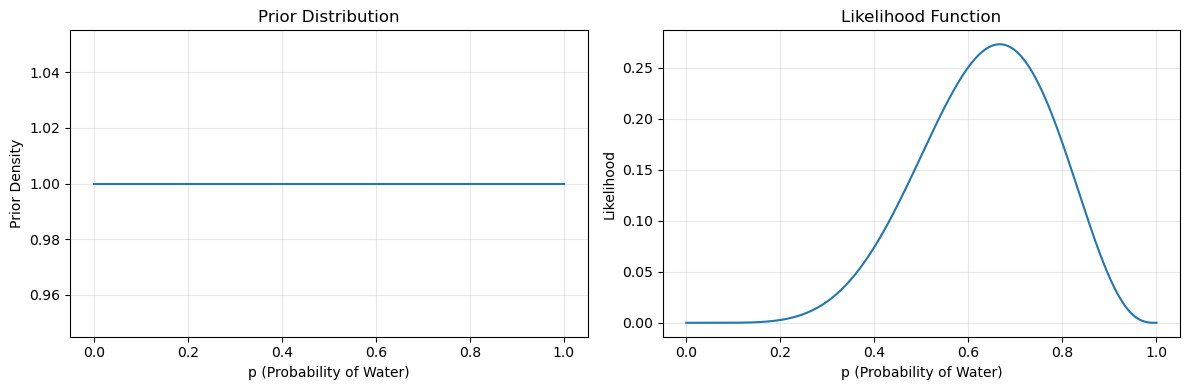

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot prior density
axes[0].plot(list(prior_samples.keys()), list(prior_samples.values()))
axes[0].set_title("Prior Distribution")
axes[0].set_xlabel("p (Probability of Water)")
axes[0].set_ylabel("Prior Density")
axes[0].grid(alpha=0.3)

# Plot likelihood
axes[1].plot(list(likelihood_samples.keys()), list(likelihood_samples.values()))
axes[1].set_title("Likelihood Function")
axes[1].set_xlabel("p (Probability of Water)")
axes[1].set_ylabel("Likelihood")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()